# Eval Metrics by Split Group, Across Boxes

Bar plots of one eval metric per split group, one bar per run, each run on its own box:

| run | box | code |
|---|---|---|
| `gastro-3k` | gastronorm | src (2026-10-08) |
| `plastic-3k` | green plastic | src (2026-10-08) |
| `s7-card-base-3k` | cardboard | src7, no outline head |

Each bar is the mean over a split's eval samples at the run's last saved epoch, from the per-sample metrics the OutputSaver wrote. Whiskers are 95% bootstrap CIs over **positions** (the speakers of a position are not independent).

Groups:
1. **In-distribution**: cube, candle, vase, soap-dispenser.
2. **Multiple objects**: two-cubes, cube-vase.
3. **Unseen object**: coffee-pot.
4. **Lid**: the same spots with and without the lid. The object is the red cube in gastro and plastic and the vase in cardboard. The older runs have one `cube-lid` split; its samples are split into with/without by the layout now on disk. A with-lid sample with a `without_lid_position_id` (its photo shows the lid, not the object) is rescored against its twin's mask, as `dataset.process_y` does now. This is only possible for `iou`; other metrics keep the old target.
5. **Laser shift**: only the lasers moved, next to the unshifted object. Plastic: `cube-shifted-lasers-1/2`. Cardboard: `vase-laser-shifted-2/3`. Gastro has none. Excluded: cardboard `vase-laser-shifted-4` (the box is rotated 90°, so the lasers hit a different face) and plastic `cube-shifted-lasers-3-backside` (the back face).

The runs differ in more than the box: data counts, speakers and code version. Read a gap between boxes as "this box's run", not a controlled effect of the box.

Env vars: `METRIC` (any per-sample metric in the saved outputs: `iou`, `com_err`, `area_rel_err`, ...; default `iou`), `RUNS` (comma-separated; default the three above).

# 1 Setup

In [1]:
import json, os
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

REPO = Path.cwd().parent
METRIC = os.environ.get("METRIC", "iou")
RUNS = os.environ.get("RUNS", "gastro-3k,plastic-3k,s7-card-base-3k").split(",")
COMBINED = "s6-gastro-plastic-cardboard-3k"  # one model trained on all 3 boxes; shown as one bar per box (run:box)
if os.environ.get("COMBINED", "1").lower() not in ("0", "false", "no", "") and COMBINED not in RUNS: RUNS.append(COMBINED)
NAMES = {"gastro-3k": "gastro", "plastic-3k": "plastic", "s7-card-base-3k": "cardboard",
         **{f"{COMBINED}:{b}": f"all boxes → {b}" for b in ("gastro", "plastic", "cardboard")}}  # display name, else the run name
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # fixed categorical order
rng = np.random.default_rng(0)

# group -> [(x label, {box: split})]. "lid:with" / "lid:without" are the lid splits relabelled by layout (section 2)
BOXES = ("gastro", "plastic", "cardboard")
LID = "\ngastro, plastic: cube\ncardboard: vase"
GROUPS = {
    "In-distribution":  [(s, {b: s for b in BOXES}) for s in ("cube", "candle", "vase", "soap-dispenser")],
    "Multiple objects": [(s, {b: s for b in BOXES}) for s in ("two-cubes", "cube-vase")],
    "Unseen object":    [("coffee-pot", {b: "coffee-pot" for b in BOXES})],
    "Lid":              [("without lid (ref)" + LID, {b: "lid:without" for b in BOXES}),
                         ("with lid" + LID,          {b: "lid:with" for b in BOXES})],
    "Laser shift":      [("no shift (ref)\nplastic: cube\ncardboard: vase", {"plastic": "cube", "cardboard": "vase"}),
                         ("shift 1 (0.5cm)\nplastic: cube-shifted-lasers-1\ncardboard: vase-laser-shifted-2", {"plastic": "cube-shifted-lasers-1", "cardboard": "vase-laser-shifted-2"}),
                         ("shift 2 (3cm)\nplastic: cube-shifted-lasers-2\ncardboard: vase-laser-shifted-3", {"plastic": "cube-shifted-lasers-2", "cardboard": "vase-laser-shifted-3"}),
                         ("other side of box\nplastic: cube-shifted-lasers-3-backside\ncardboard: vase-laser-shifted-4", {"plastic": "cube-shifted-lasers-3-backside", "cardboard": "vase-laser-shifted-4"})],
}
LID_SPLITS = {"cube-lid", "cube-with-lid", "cube-without-lid", "vase-lid", "vase-with-lid", "vase-without-lid"}
print("metric", METRIC, "| runs", RUNS)

metric iou | runs ['gastro-3k', 'plastic-3k', 's7-card-base-3k', 's6-gastro-plastic-cardboard-3k']


# 2 Load Per-Sample Metrics

One row per (run, split, position, speaker) at each run's last saved eval epoch, with the sample's layout. Lid samples are relabelled `lid:with` / `lid:without` from their layout. With-lid samples that have a twin are rescored against the twin's mask: `03_smask.png` BOX-resized to the prediction's size, soft IoU = sum(min) / sum(max), as in `arch.iou`.

Train positions per bar: the run's `positions/train.txt` entries recorded under the same layouts as the bar's eval samples.

In [2]:
def load_meta(d): return {k: v for l in (d / "metadata.jsonl").read_text().splitlines() if l.strip() for k, v in json.loads(l).items()}

samples, layouts, loaded = {}, {}, set()  # (exp, pos, spk) -> (dir, meta); (exp, pos) -> layout
def sample(exp, pos, spk=None):
    if exp not in loaded:
        loaded.add(exp)
        for d in (REPO / "experiments" / exp / "samples").iterdir():
            if (d / "metadata.jsonl").exists():
                m = load_meta(d); samples[exp, m["position_id"], m["speaker"]] = (d, m); layouts[exp, m["position_id"]] = m.get("layout")
    return samples[exp, pos, spk] if spk is not None else layouts.get((exp, pos))

def mask(d, h, w):
    img = Image.open(d / "image/03_smask.png").convert("F").resize((w, h), Image.BOX)
    return torch.from_numpy(np.clip(np.asarray(img, np.float32) / 255, 0, 1))

def soft_iou(pred, true): return float(torch.minimum(pred, true).sum() / torch.maximum(pred, true).sum().clamp_min(1e-6))

def lid_gt(exp, pos, spk):
    # with-lid overhead masks are junk (lid covers the box), so the GT is the uncovered capture recorded right before:
    # same object, same spot, lid off. Always pos - 1 (metadata's without_lid_position_id is missing for gastro 1255)
    d, m = sample(exp, pos - 1, spk)
    assert "without-lid" in m["layout"], (exp, pos, m["layout"])
    return d

def lid_eval(run, pred, exp, pos, spk, m, v):
    # (split name, value) for one lid sample: with-lid IoU is recomputed against lid_gt; other metrics can't be fixed -> NaN
    if "with-lid" not in m["layout"]: return "lid:without", v
    if METRIC != "iou": return "lid:with", np.nan
    pred = pred.float()
    return "lid:with", soft_iou(pred, mask(lid_gt(exp, pos, spk), *pred.shape))

def load(run):
    H = REPO / "runs" / run / "outputs_history" / "eval"
    ep = max(int(f.name[2:6]) for f in H.rglob("ep*.pt"))
    rows = []
    for f in sorted(H.rglob(f"ep{ep:04d}-*.pt")):
        d = torch.load(f, weights_only=False)
        box, split, i = f.parent.parent.name, f.parent.name, d["info"]
        for j, (exp, p, s) in enumerate(zip(i["experiment"], i["position_id"].tolist(), i["speaker"].tolist())):
            sd, m = sample(exp, p, s)
            v, name = float(d["metrics"][METRIC][j]), split
            if split in LID_SPLITS: name, v = lid_eval(run, d["mask_pred"][j], exp, p, s, m, v)
            rows.append(dict(run=run, ep=ep, box=box, exp=exp, split=name, layout=m.get("layout"), pos=p, spk=s, value=v))
    return pd.DataFrame(rows)

df = pd.concat([load(r) for r in RUNS], ignore_index=True)
train = {r: Counter((e, sample(e, int(p))) for e, p in (l.split() for l in (REPO / "runs" / r / "positions/train.txt").read_text().splitlines())) for r in RUNS}  # run -> (exp, layout) -> n train positions
# runs evaluated on several boxes become one pseudo-run per box, "run:box"
multi = df.groupby("run").box.nunique() > 1
RUNS = [x for r in RUNS for x in ([f"{r}:{b}" for b in BOXES if ((df.run == r) & (df.box == b)).any()] if multi[r] else [r])]
df["run"] = np.where(df.run.map(multi), df.run + ":" + df.box, df.run)
# each box keeps one color; a "run:box" bar sits right after that box's single-box run, same color, hatched
BOX_OF = {r: df[df.run == r].box.iloc[0] for r in RUNS}
single = [r for r in RUNS if ":" not in r]
COLOR = {r: COLORS[k] for k, r in enumerate(single)}
for r in RUNS:
    if ":" in r: COLOR[r] = next((COLOR[s] for s in single if BOX_OF[s] == BOX_OF[r]), COLORS[len(COLOR) % len(COLORS)])
RUNS = [x for s in single for x in [s] + [r for r in RUNS if ":" in r and BOX_OF[r] == BOX_OF[s]]] + \
       [r for r in RUNS if ":" in r and BOX_OF[r] not in {BOX_OF[s] for s in single}]
df.groupby("run", sort=False).agg(epoch=("ep", "first"), samples=("value", "size"), mean=("value", "mean")).round(3)

,epoch,samples,mean
run,,,
gastro-3k,3000,956,0.472
plastic-3k,3000,1395,0.579
s7-card-base-3k,3000,1758,0.310
s6-gastro-plastic-cardboard-3k:cardboard,3000,1994,0.314
s6-gastro-plastic-cardboard-3k:gastro,3000,956,0.484
s6-gastro-plastic-cardboard-3k:plastic,3000,1846,0.572


# 3 Bar Plots

In [3]:
def ci(g):
    # 95% bootstrap CI of the mean, resampling positions
    per_pos = g.groupby("pos").value.agg(["sum", "count"]).values
    if len(per_pos) < 2: return np.nan, np.nan
    idx = rng.integers(0, len(per_pos), (1000, len(per_pos)))
    return np.percentile(per_pos[idx, 0].sum(1) / per_pos[idx, 1].sum(1), [2.5, 97.5])

def stats(group):
    out = []
    for x, (item, splits) in enumerate(GROUPS[group]):
        for k, run in enumerate(RUNS):
            g = df[(df.run == run) & (df.split == splits.get(df[df.run == run].box.iloc[0], ""))]
            if len(g): out.append(dict(x=x, item=item, k=k, run=NAMES.get(run, run), mean=g.value.mean(), lo=ci(g)[0], hi=ci(g)[1],
                                       n_train=sum(train[run.split(":")[0]][k] for k in set(zip(g.exp, g.layout))), n_test=g.pos.nunique()))
    return pd.DataFrame(out)

def bars(group):
    t, w = stats(group), 0.8 / len(RUNS)
    fig, ax = plt.subplots(figsize=(13, 4.6))
    for k, run in enumerate(RUNS):
        tk = t[t.k == k]
        if tk.empty: continue
        x = tk.x + (k - (len(RUNS) - 1) / 2) * w
        if ":" in run: ax.bar(x, tk["mean"], w * 0.92, facecolor=COLOR[run] + "40", edgecolor=COLOR[run], hatch="////", linewidth=1, label=NAMES.get(run, run))
        else: ax.bar(x, tk["mean"], w * 0.92, color=COLOR[run], label=NAMES.get(run, run))
        ax.errorbar(x, tk["mean"], yerr=[tk["mean"] - tk.lo, tk.hi - tk["mean"]], fmt="none", ecolor="#52514e", elinewidth=1)
        for xi, m, top in zip(x, tk["mean"], np.fmax(tk["mean"], tk.hi)):  # above the whisker
            ax.annotate(f"{m:.2f}", (xi, top), xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=8)
        for xi, a, b in zip(x, tk.n_train, tk.n_test):
            ax.annotate(f"tr {a}\nte {b}", (xi, 0), xytext=(0, -4), textcoords="offset points", ha="center", va="top", fontsize=6.5, color="#52514e")
    ax.set_xticks(range(len(GROUPS[group])), [item for item, _ in GROUPS[group]], fontsize=9)
    ax.tick_params(axis="x", pad=26, length=0)
    ax.set_ylabel(METRIC)
    ax.set_title(group, loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e5e4e0", linewidth=0.8); ax.set_axisbelow(True)
    ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout(); plt.show()
    return t

def table(t): return t.assign(item=t.item.str.split("\n").str[0]).pivot_table(index="item", columns="run", values=["mean", "n_train", "n_test"], sort=False).round(3)
tables = {}

## In-distribution

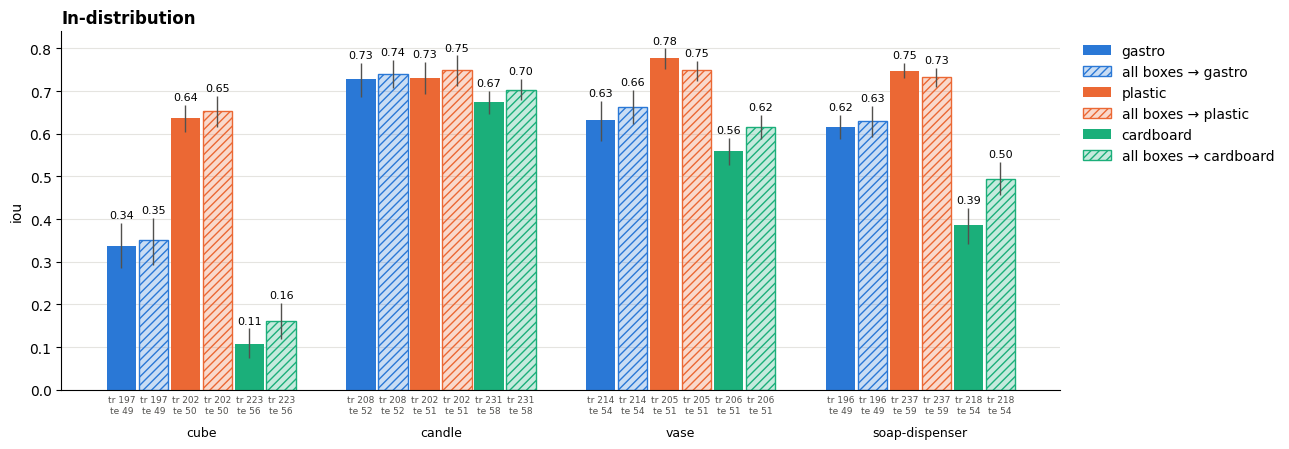

mean                                                 \
run            gastro all boxes → gastro plastic all boxes → plastic   
item                                                                   
cube            0.338              0.351   0.637               0.653   
candle          0.729              0.741   0.732               0.749   
vase            0.633              0.663   0.777               0.748   
soap-dispenser  0.616              0.630   0.748               0.733   

                                               n_train                     \
run            cardboard all boxes → cardboard  gastro all boxes → gastro   
item                                                                        
cube               0.109                 0.161   197.0              197.0   
candle             0.674                 0.703   208.0              208.0   
vase               0.558                 0.616   214.0              214.0   
soap-dispenser     0.385                 0.495   196.0              196.0   

                                                                            \
run            plastic all boxes → plastic cardboard all boxes → cardboard   
item                                                                         
cube             202.0               202.0     223.0                 223.0   
candle           202.0               202.0     231.0                 231.0   
vase             205.0               205.0     206.0                 206.0   
soap-dispenser   237.0               237.0     218.0                 218.0   

               n_test                                                 \
run            gastro all boxes → gastro plastic all boxes → plastic   
item                                                                   
cube             49.0               49.0    50.0                50.0   
candle           52.0               52.0    51.0                51.0   
vase             54.0               54.0    51.0                51.0   
soap-dispenser   49.0               49.0    59.0                59.0   

                                                
run            cardboard all boxes → cardboard  
item                                            
cube                56.0                  56.0  
candle              58.0                  58.0  
vase                51.0                  51.0  
soap-dispenser      54.0                  54.0

In [4]:
tables["In-distribution"] = bars("In-distribution")
table(tables["In-distribution"])

## Multiple objects

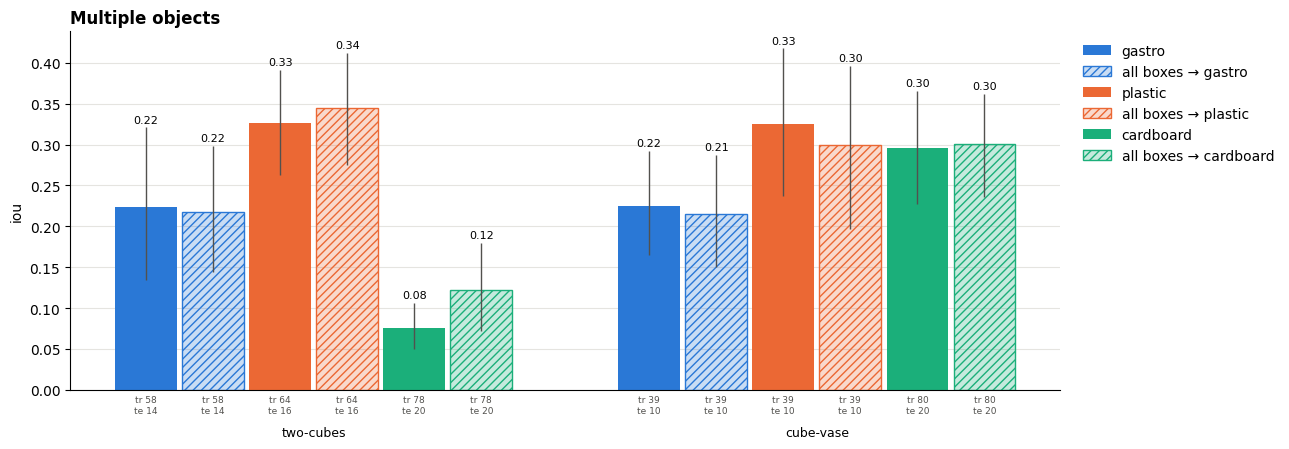

mean                                                           \
run       gastro all boxes → gastro plastic all boxes → plastic cardboard   
item                                                                        
two-cubes  0.224              0.218   0.327               0.345     0.076   
cube-vase  0.224              0.215   0.326               0.299     0.296   

                                n_train                             \
run       all boxes → cardboard  gastro all boxes → gastro plastic   
item                                                                 
two-cubes                 0.122    58.0               58.0    64.0   
cube-vase                 0.300    39.0               39.0    39.0   

                                                              n_test  \
run       all boxes → plastic cardboard all boxes → cardboard gastro   
item                                                                   
two-cubes                64.0      78.0                  78.0   14.0   
cube-vase                39.0      80.0                  80.0   10.0   

                                                                    \
run       all boxes → gastro plastic all boxes → plastic cardboard   
item                                                                 
two-cubes               14.0    16.0                16.0      20.0   
cube-vase               10.0    10.0                10.0      20.0   

                                 
run       all boxes → cardboard  
item                             
two-cubes                  20.0  
cube-vase                  20.0

In [5]:
tables["Multiple objects"] = bars("Multiple objects")
table(tables["Multiple objects"])

## Unseen object

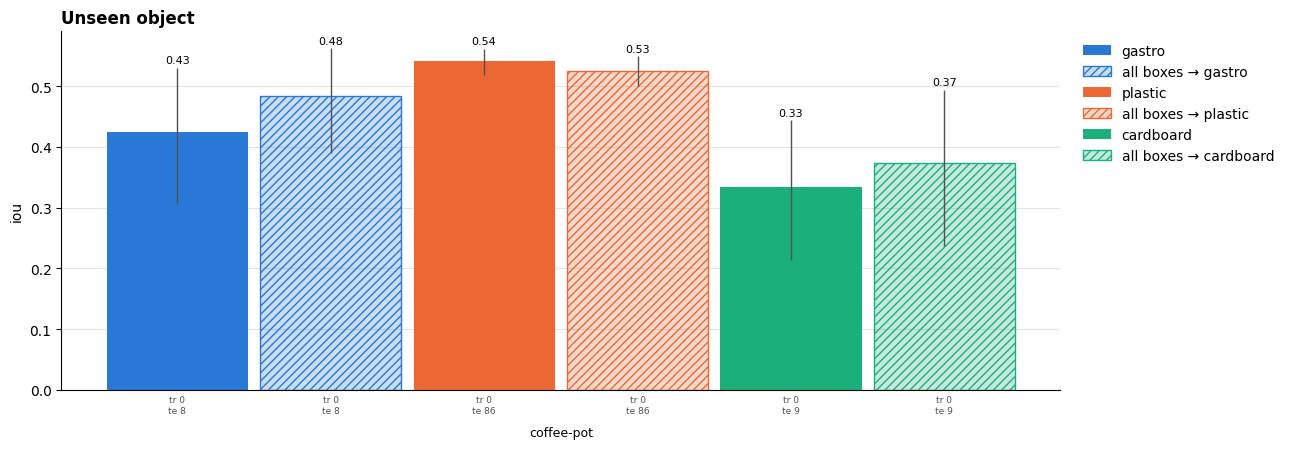

mean                                                           \
run        gastro all boxes → gastro plastic all boxes → plastic cardboard   
item                                                                         
coffee-pot  0.425              0.484   0.542               0.525     0.335   

                                 n_train                             \
run        all boxes → cardboard  gastro all boxes → gastro plastic   
item                                                                  
coffee-pot                 0.374     0.0                0.0     0.0   

                                                               n_test  \
run        all boxes → plastic cardboard all boxes → cardboard gastro   
item                                                                    
coffee-pot                 0.0       0.0                   0.0    8.0   

                                                                     \
run        all boxes → gastro plastic all boxes → plastic cardboard   
item                                                                  
coffee-pot                8.0    86.0                86.0       9.0   

                                  
run        all boxes → cardboard  
item                              
coffee-pot                   9.0

In [6]:
tables["Unseen object"] = bars("Unseen object")
table(tables["Unseen object"])

## Lid

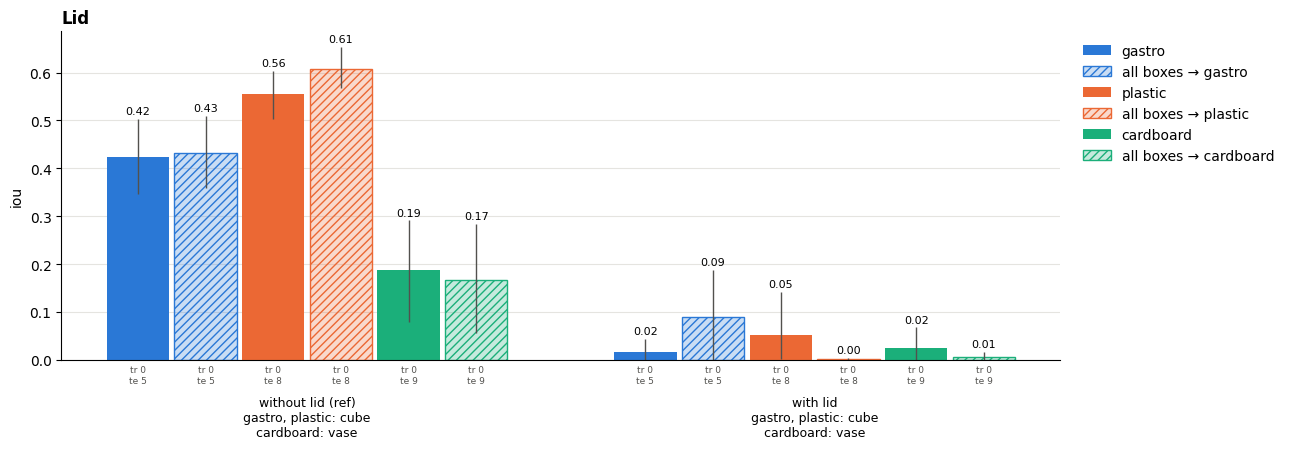

mean                                                 \
run               gastro all boxes → gastro plastic all boxes → plastic   
item                                                                      
without lid (ref)  0.423              0.432   0.555               0.608   
with lid           0.017              0.089   0.052               0.002   

                                                  n_train                     \
run               cardboard all boxes → cardboard  gastro all boxes → gastro   
item                                                                           
without lid (ref)     0.189                 0.166     0.0                0.0   
with lid              0.024                 0.005     0.0                0.0   

                                                                               \
run               plastic all boxes → plastic cardboard all boxes → cardboard   
item                                                                            
without lid (ref)     0.0                 0.0       0.0                   0.0   
with lid              0.0                 0.0       0.0                   0.0   

                  n_test                                                 \
run               gastro all boxes → gastro plastic all boxes → plastic   
item                                                                      
without lid (ref)    5.0                5.0     8.0                 8.0   
with lid             5.0                5.0     8.0                 8.0   

                                                   
run               cardboard all boxes → cardboard  
item                                               
without lid (ref)       9.0                   9.0  
with lid                9.0                   9.0

In [7]:
tables["Lid"] = bars("Lid")
table(tables["Lid"])

## Laser shift

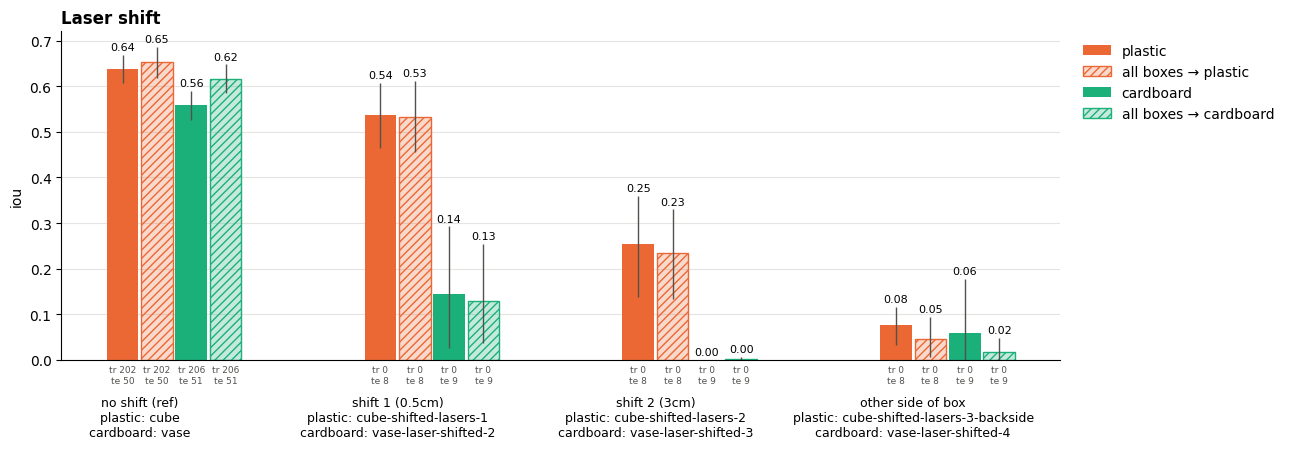

mean                                                      \
run               plastic all boxes → plastic cardboard all boxes → cardboard   
item                                                                            
no shift (ref)      0.637               0.653     0.558                 0.616   
shift 1 (0.5cm)     0.537               0.533     0.145                 0.129   
shift 2 (3cm)       0.255               0.234     0.000                 0.002   
other side of box   0.075               0.045     0.059                 0.016   

                  n_train                                                      \
run               plastic all boxes → plastic cardboard all boxes → cardboard   
item                                                                            
no shift (ref)      202.0               202.0     206.0                 206.0   
shift 1 (0.5cm)       0.0                 0.0       0.0                   0.0   
shift 2 (3cm)         0.0                 0.0       0.0                   0.0   
other side of box     0.0                 0.0       0.0                   0.0   

                   n_test                                                      
run               plastic all boxes → plastic cardboard all boxes → cardboard  
item                                                                           
no shift (ref)       50.0                50.0      51.0                  51.0  
shift 1 (0.5cm)       8.0                 8.0       9.0                   9.0  
shift 2 (3cm)         8.0                 8.0       9.0                   9.0  
other side of box     8.0                 8.0       9.0                   9.0

In [8]:
tables["Laser shift"] = bars("Laser shift")
table(tables["Laser shift"])

# 4 Group Means

Each group's mean over its non-reference items (each split counts once).

In [9]:
pd.DataFrame({g: t[~t.item.str.contains("(ref)", regex=False)].groupby("run")["mean"].mean() for g, t in tables.items()}).reindex([NAMES.get(r, r) for r in RUNS]).round(3)

,In-distribution,Multiple objects,Unseen object,Lid,Laser shift
run,,,,,
gastro,0.579,0.224,0.425,0.017,NaN
all boxes → gastro,0.596,0.216,0.484,0.089,NaN
plastic,0.724,0.326,0.542,0.052,0.289
all boxes → plastic,0.721,0.322,0.525,0.002,0.271
cardboard,0.432,0.186,0.335,0.024,0.068
all boxes → cardboard,0.494,0.211,0.374,0.005,0.049


# 5 Trends

Written 2026-10-13 from the defaults (`METRIC=iou`, all three runs at epoch 3000). The three runs differ in data, speakers and code as well as the box. Lid, coffee-pot and laser-shift splits are 9–10 positions each, so their CIs are wide.

1. **Plastic > gastro > cardboard, almost everywhere.** Group means: in-distribution 0.724 / 0.579 / 0.432, multiple objects 0.326 / 0.224 / 0.186, coffee-pot 0.542 / 0.425 / 0.335. The ranking holds in every group except laser shift (no gastro) and lid (all ≈ 0).
2. **The box gap is mostly the small objects.** Candle is ~0.7 in all three boxes (0.729 / 0.732 / 0.674). The cube swings 0.637 / 0.338 / 0.109, and soap-dispenser 0.748 / 0.616 / 0.385. The cardboard cube is poor on every layout, not just the random poses: cube-grid-1 0.074, cube-grid-2 0.207, cube-random-pos2 0.064, cube-random_poses 0.053.
3. **Two identical cubes is hard in every box; cube + vase isn't.** two-cubes: 0.327 / 0.224 / 0.076, at or below the single cube. cube-vase: 0.326 / 0.224 / 0.296. Cardboard is close to plastic here because the vase, which cardboard does well, carries the score.
4. **Unseen objects generalise at about the same rate in every box.** coffee-pot over the in-distribution mean: 0.73 (gastro), 0.75 (plastic), 0.78 (cardboard). So the cardboard deficit on coffee-pot is the same deficit it has on trained objects, not a worse generalisation.
5. **With the lid on, every box fails.** With lid: 0.004 / 0.052 / 0.024, against 0.423 / 0.555 / 0.189 for the same spots without the lid. The plastic and cardboard with-lid samples are scored against the twin's mask; gastro's lid photos still show the cube. This is the one failure that is universal and total.
6. **Laser shifts hurt cardboard much more than plastic.** Plastic degrades gradually: 0.637 → 0.537 (shift 1) → 0.255 (shift 2). Cardboard collapses: 0.558 → 0.145 → 0.000. Cardboard's model depends much more on the exact laser placement, consistent with a weaker, more position-specific signal on that box.

The good cases (candle, vase) are box-independent. The cardboard deficit is concentrated in the cube and soap-dispenser, which are small or light. Lid and two identical objects are failures common to all boxes.